# Model validation of 2D outputs
Note: this notebook requires the model output data, which can be downloaded from, zenodo.

In [1]:
import mikeio
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd
import glob

In [2]:
ms.options.metrics.list = ["urmse", "mae", "cc", "si", "r2"]

In [3]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "2D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

Model results data are stored in a dfsu file. We can use [MIKE IO](https://dhi.github.io/mikeio) read the data to a MIKE IO Dataset.


In [4]:
ds = mikeio.read(f"{mr_fldr}{mr_fn}", items="*Surf*")
ds.items

[Surface elevation <Surface Elevation> (meter)]

## Compare to measurements

Load water level data

In [ ]:
df_stn = pd.read_csv(obs_fldr + "stations_wl.csv", index_col=0)

q = ms.Quantity(name="Surface Elevation", unit="meter")
wllist = []
for i, row in df_stn.iterrows():
    df = pd.read_csv(obs_fldr + f"{i}_wl.csv", index_col=0)
    df.index = pd.to_datetime(df.index, format="ISO8601")
    o = ms.PointObservation(df.water_level, x=row['Longitude'], y=row['Latitude'], name=i, quantity=q)
    wllist.append(o)

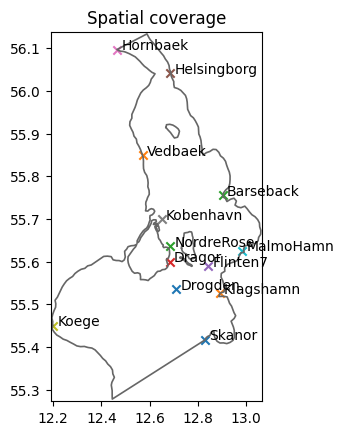

In [ ]:
msh = mikeio.open("../input/mesh_EMOD.mesh")
ms.plotting.spatial_overview(wllist, mod=msh);

In [ ]:
cmps = []
da = ds[0]
model_time = pd.DatetimeIndex(ds.time.to_pydatetime())
model_values = da.to_numpy()

for o in wllist:
    # Extract nearest model element and build a point model result
    eid = da.geometry.find_index(coords=(o.x, o.y))[0]
    mser = pd.Series(model_values[:, eid], index=model_time)
    pmr = ms.PointModelResult(mser, x=o.x, y=o.y, name="MIKE3")

    try:
        cmp = ms.match(obs=o, mod=pmr, obs_no_overlap="warn")
        if cmp is not None:
            cmps.append(cmp.remove_bias())
    except Exception as e:
        print(f"{o.name}: {e}")

cc = ms.ComparerCollection(cmps)

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\timeseries\_timeseries.py:412: UserWarning: No data left after trimming to 2022-12-31 23:59:59 - 2025-12-31 23:00:01
  warnings.warn(msg)


<Axes: >

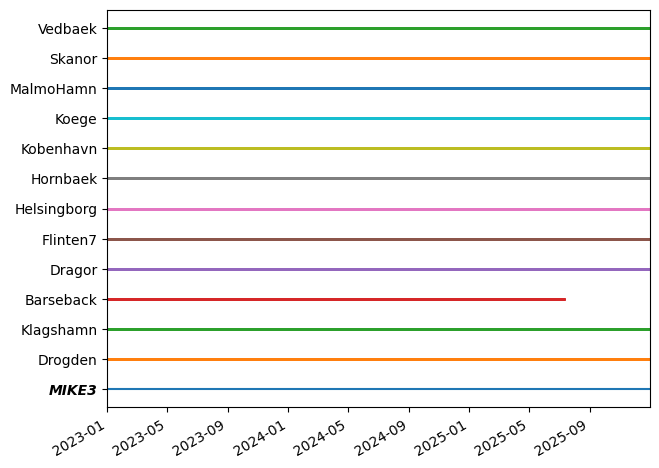

In [ ]:
cc.plot.temporal_coverage()

### Skill table

In [ ]:
cc.skill().round(3)

,n,urmse,mae,cc,si,r2
observation,,,,,,
Drogden,51509,0.069,0.054,0.940,0.370,0.857
Klagshamn,26264,0.074,0.056,0.945,0.318,0.811
Barseback,21820,0.106,0.070,0.793,0.522,0.608
Dragor,52034,0.070,0.051,0.905,0.366,0.783
Flinten7,25643,0.099,0.069,0.812,0.479,0.502
Helsingborg,25933,0.075,0.055,0.892,0.385,0.793
Hornbaek,51558,0.075,0.058,0.950,0.408,0.885
Kobenhavn,51212,0.115,0.087,0.761,0.563,0.570
Koege,51440,0.074,0.054,0.941,0.369,0.856


### Example timeseries

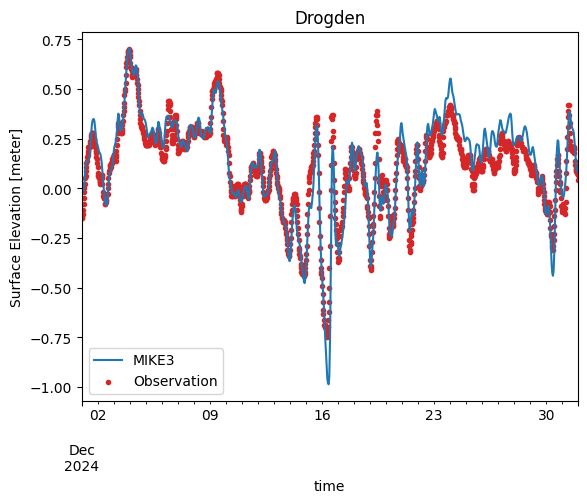

In [ ]:
plot_all = False
if not plot_all:
    cc["Drogden"].sel(time=slice("2024-12-01","2024-12-31")).plot.timeseries();
else:
    for cmp in cc:
        cmp.sel(time=slice("2024-12-01","2024-12-31")).plot.timeseries();
        if save_png:
            plt.savefig(f"{fig_fldr}modelskill_timeseries_{cmp.name}.png", bbox_inches='tight');

### Scatter plots
The scatter plots are saved in the figures folder. If the fitted line follows the 1:1 line, there is a perfect correspondance between data and model outputs. In our case, there are some discrepancies, e.g. for the Kobenhavn station. Some of these discrepancies might be due to representation errors, ie. when the model simply is including dynamics which we know are present, e.g. high-frequency dynamics within a harbor, where the measurement station might be placed.

In [ ]:
for cmp in cc:
    cmp.plot.scatter(skill_table=True, figsize=(6,5), bins=40);
    if save_png:
        plt.savefig(f"{fig_fldr}modelskill_comparison_{cmp.name}.png", bbox_inches='tight');
        plt.close()

c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000 points in plot. Set `show_points` to True to show all points.
  warnings.warn(
c:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund\.venv\Lib\site-packages\modelskill\plotting\_misc.py:83: UserWarning: Showing only 50000

## Compare to altimetry data

In [5]:
sat_files =sorted(glob.glob(obs_fldr + "Altimetry_wl_*.csv"))
missions = [f.split("_")[2].split(".")[0] for f in sat_files]
q = ms.Quantity(name="Surface Elevation", unit="meter")
altlist = []
for m in missions:
    df = pd.read_csv(obs_fldr + f"Altimetry_wl_{m}.csv", index_col=0)
    df.index = pd.to_datetime(df.index, format="ISO8601")
    o = ms.TrackObservation(df, item="water_level", x_item="longitude", y_item="latitude", name=m, quantity=q)
    altlist.append(o)

In [6]:
mr = ms.DfsuModelResult(mr_fldr+mr_fn, name="MIKE3", item=1)
mr

<DfsuModelResult>: MIKE3
Time: 2023-01-01 00:00:00 - 2025-12-31 23:00:00
Quantity: u velocity component [m/s]

In [7]:
cmps = []
match_t = "2025" # You can choose a specific time period here
for o in altlist:
    print(f"Processing {o.name}...")
    try:
        cmp = ms.match(obs=o.sel(time=match_t), mod=mr) 
        cmps.append(cmp.remove_bias())
    except Exception as e:
        print(e)    
cc = ms.ComparerCollection(cmps)

Processing 3a...
Processing 3b...
Processing c2...
Processing j3...
Processing sa...


In [8]:
cc.skill().round(4)

,n,urmse,mae,cc,si,r2
observation,,,,,,
3a,23,0.1568,0.1276,0.4000,0.7208,0.1405
3b,32,0.1650,0.1425,0.3134,0.7798,0.0970
c2,44,0.4141,0.2429,0.0635,0.9879,-0.0302
j3,39,0.1714,0.1437,0.4270,1.0408,0.1802
sa,35,0.2403,0.1886,-0.1530,0.9742,-0.3911


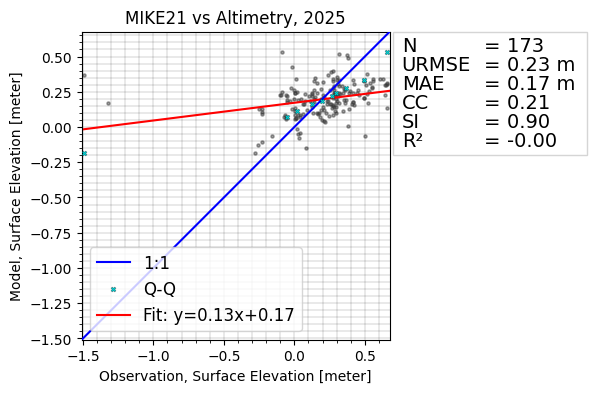

In [9]:
cc.plot.scatter(skill_table=True, figsize=(5,4));
plt.title("MIKE21 vs Altimetry, "+match_t)
if save_png: plt.savefig("../figures/altimetry_comparison.png", bbox_inches="tight")

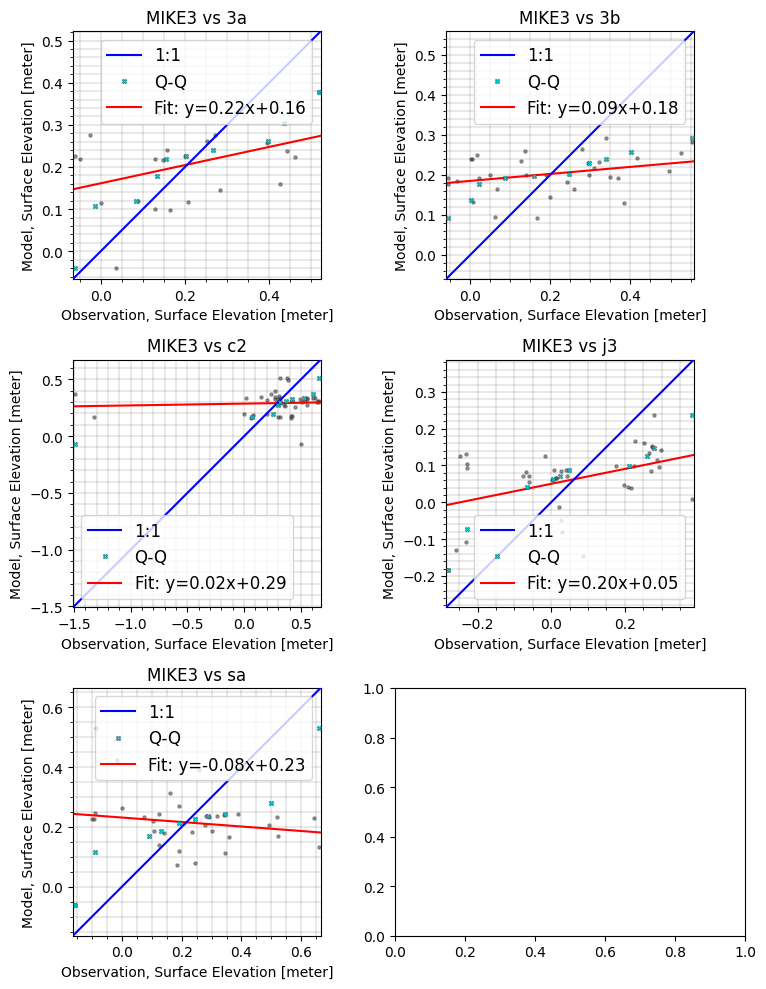

In [10]:
fig, axs = plt.subplots(-(-len(cc)//2), 2, figsize=(8,len(cc)*2))
axs = axs.flatten()
for i in range(len(cc)):
    cc[i].sel().plot.scatter(ax=axs[i])

# axs[-1].axis("off")
plt.tight_layout()
plt.show()